In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# Steps to path on this challenge

1. Understand the problem


2. Load Datasets to the environment


3. Understand the Dataset

4. Perform the EDA

5. Data preproccess and Feature Engineering


6. Model selection and Training


7. Perform inference on test datasets

8. Generating submision csv




In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
np.random.seed(42)
import os

import warnings
warnings.filterwarnings('ignore')

In [ ]:
Base_Dir='/content/drive/MyDrive/ FFS_Basket'
Output_Dir='/content/drive/MyDrive/ FFS_Basket_output'

train=pd.read_csv(Base_Dir+'/Train.csv')
test=pd.read_csv(Base_Dir+'/Test.csv')
sus=pd.read_csv(Base_Dir+'/SampleSubmission.csv')
cusm=pd.read_csv(Base_Dir+'/customer_data.csv')
sku=pd.read_csv(Base_Dir+'/sku_data.csv')

# Stage perform EDA

In [ ]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2114436 entries, 0 to 2114435
Data columns (total 20 columns):
 #   Column                    Dtype  
---  ------                    -----  
 0   ID                        object 
 1   customer_id               int64  
 2   product_unit_variant_id   int64  
 3   week_start                object 
 4   qty_this_week             float64
 5   num_orders_week           float64
 6   spend_this_week           float64
 7   purchased_this_week       int64  
 8   product_id                int64  
 9   grade_name                object 
 10  unit_name                 object 
 11  product_grade_variant_id  int64  
 12  selling_price             float64
 13  customer_category         object 
 14  customer_status           object 
 15  customer_created_at       object 
 16  Target_qty_next_1w        float64
 17  Target_purchase_next_1w   int64  
 18  Target_qty_next_2w        float64
 19  Target_purchase_next_2w   int64  
dtypes: float64(6), int64(7),

In [ ]:
train.describe()

,customer_id,product_unit_variant_id,qty_this_week,num_orders_week,spend_this_week,purchased_this_week,product_id,product_grade_variant_id,selling_price,Target_qty_next_1w,Target_purchase_next_1w,Target_qty_next_2w,Target_purchase_next_2w
count,2.114436e+06,2.114436e+06,2.114436e+06,2.114436e+06,2.114436e+06,2.114436e+06,2.114436e+06,2.114436e+06,2.114436e+06,2.114436e+06,2.114436e+06,2.114436e+06,2.114436e+06
mean,5.646525e+02,2.170153e+02,1.072292e+00,3.993926e-02,7.529062e+02,2.017323e-02,1.536288e+02,1.834540e+02,3.838566e+02,1.079259e+00,2.060502e-02,2.224129e+00,2.771614e-02
std,1.276974e+02,1.615009e+02,2.820136e+02,3.524010e-01,1.133429e+04,1.405926e-01,1.391962e+02,1.525540e+02,1.031628e+03,2.820153e+02,1.420580e-01,4.767044e+02,1.641584e-01
min,3.390000e+02,1.000000e+00,0.000000e+00,0.000000e+00,-1.347000e+04,0.000000e+00,1.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,4.500000e+02,8.800000e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,5.100000e+01,6.500000e+01,6.500000e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,5.510000e+02,1.775000e+02,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.095000e+02,1.405000e+02,1.350000e+02,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
75%,6.760000e+02,3.000000e+02,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.970000e+02,2.610000e+02,2.800000e+02,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
max,7.820000e+02,6.550000e+02,1.404000e+05,2.200000e+01,8.054150e+05,1.000000e+00,5.680000e+02,6.150000e+02,9.000000e+03,1.404000e+05,1.000000e+00,2.704000e+05,1.000000e+00


In [ ]:
test.describe()

,customer_id,product_unit_variant_id,product_id,product_grade_variant_id
count,275796.000000,275796.000000,275796.000000,275796.000000
mean,564.652482,217.015337,153.628834,183.453988
std,127.697623,161.501142,139.196390,152.554208
min,339.000000,1.000000,1.000000,1.000000
25%,450.000000,88.000000,51.000000,65.000000
50%,551.000000,177.500000,109.500000,140.500000
75%,676.000000,300.000000,197.000000,261.000000
max,782.000000,655.000000,568.000000,615.000000


In [ ]:
train_columns_list=train.columns.to_list()

In [ ]:
test_columns_list=test.columns.to_list()

# Numerical columns

In [ ]:
#train numerical columns
for col in train_columns_list:
  if train[col].dtype == 'int64' or train[col].dtype == 'float64':
    print(col)

customer_id
product_unit_variant_id
qty_this_week
num_orders_week
spend_this_week
purchased_this_week
product_id
product_grade_variant_id
selling_price
Target_qty_next_1w
Target_purchase_next_1w
Target_qty_next_2w
Target_purchase_next_2w


In [ ]:
#test numerical columns
for col in test_columns_list:
  if test[col].dtype == 'int64' or test[col].dtype == 'float64':
    print(col)

customer_id
product_unit_variant_id
product_id
product_grade_variant_id


# Categorical columns

In [ ]:
for col in train_columns_list:
  if train[col].dtype=='object':
    print(col)

ID
week_start
grade_name
unit_name
customer_category
customer_status
customer_created_at


In [ ]:
for col in test_columns_list:
  if test[col].dtype=='object':
    print(col)

ID
week_start
grade_name
unit_name
customer_category
customer_status
customer_created_at


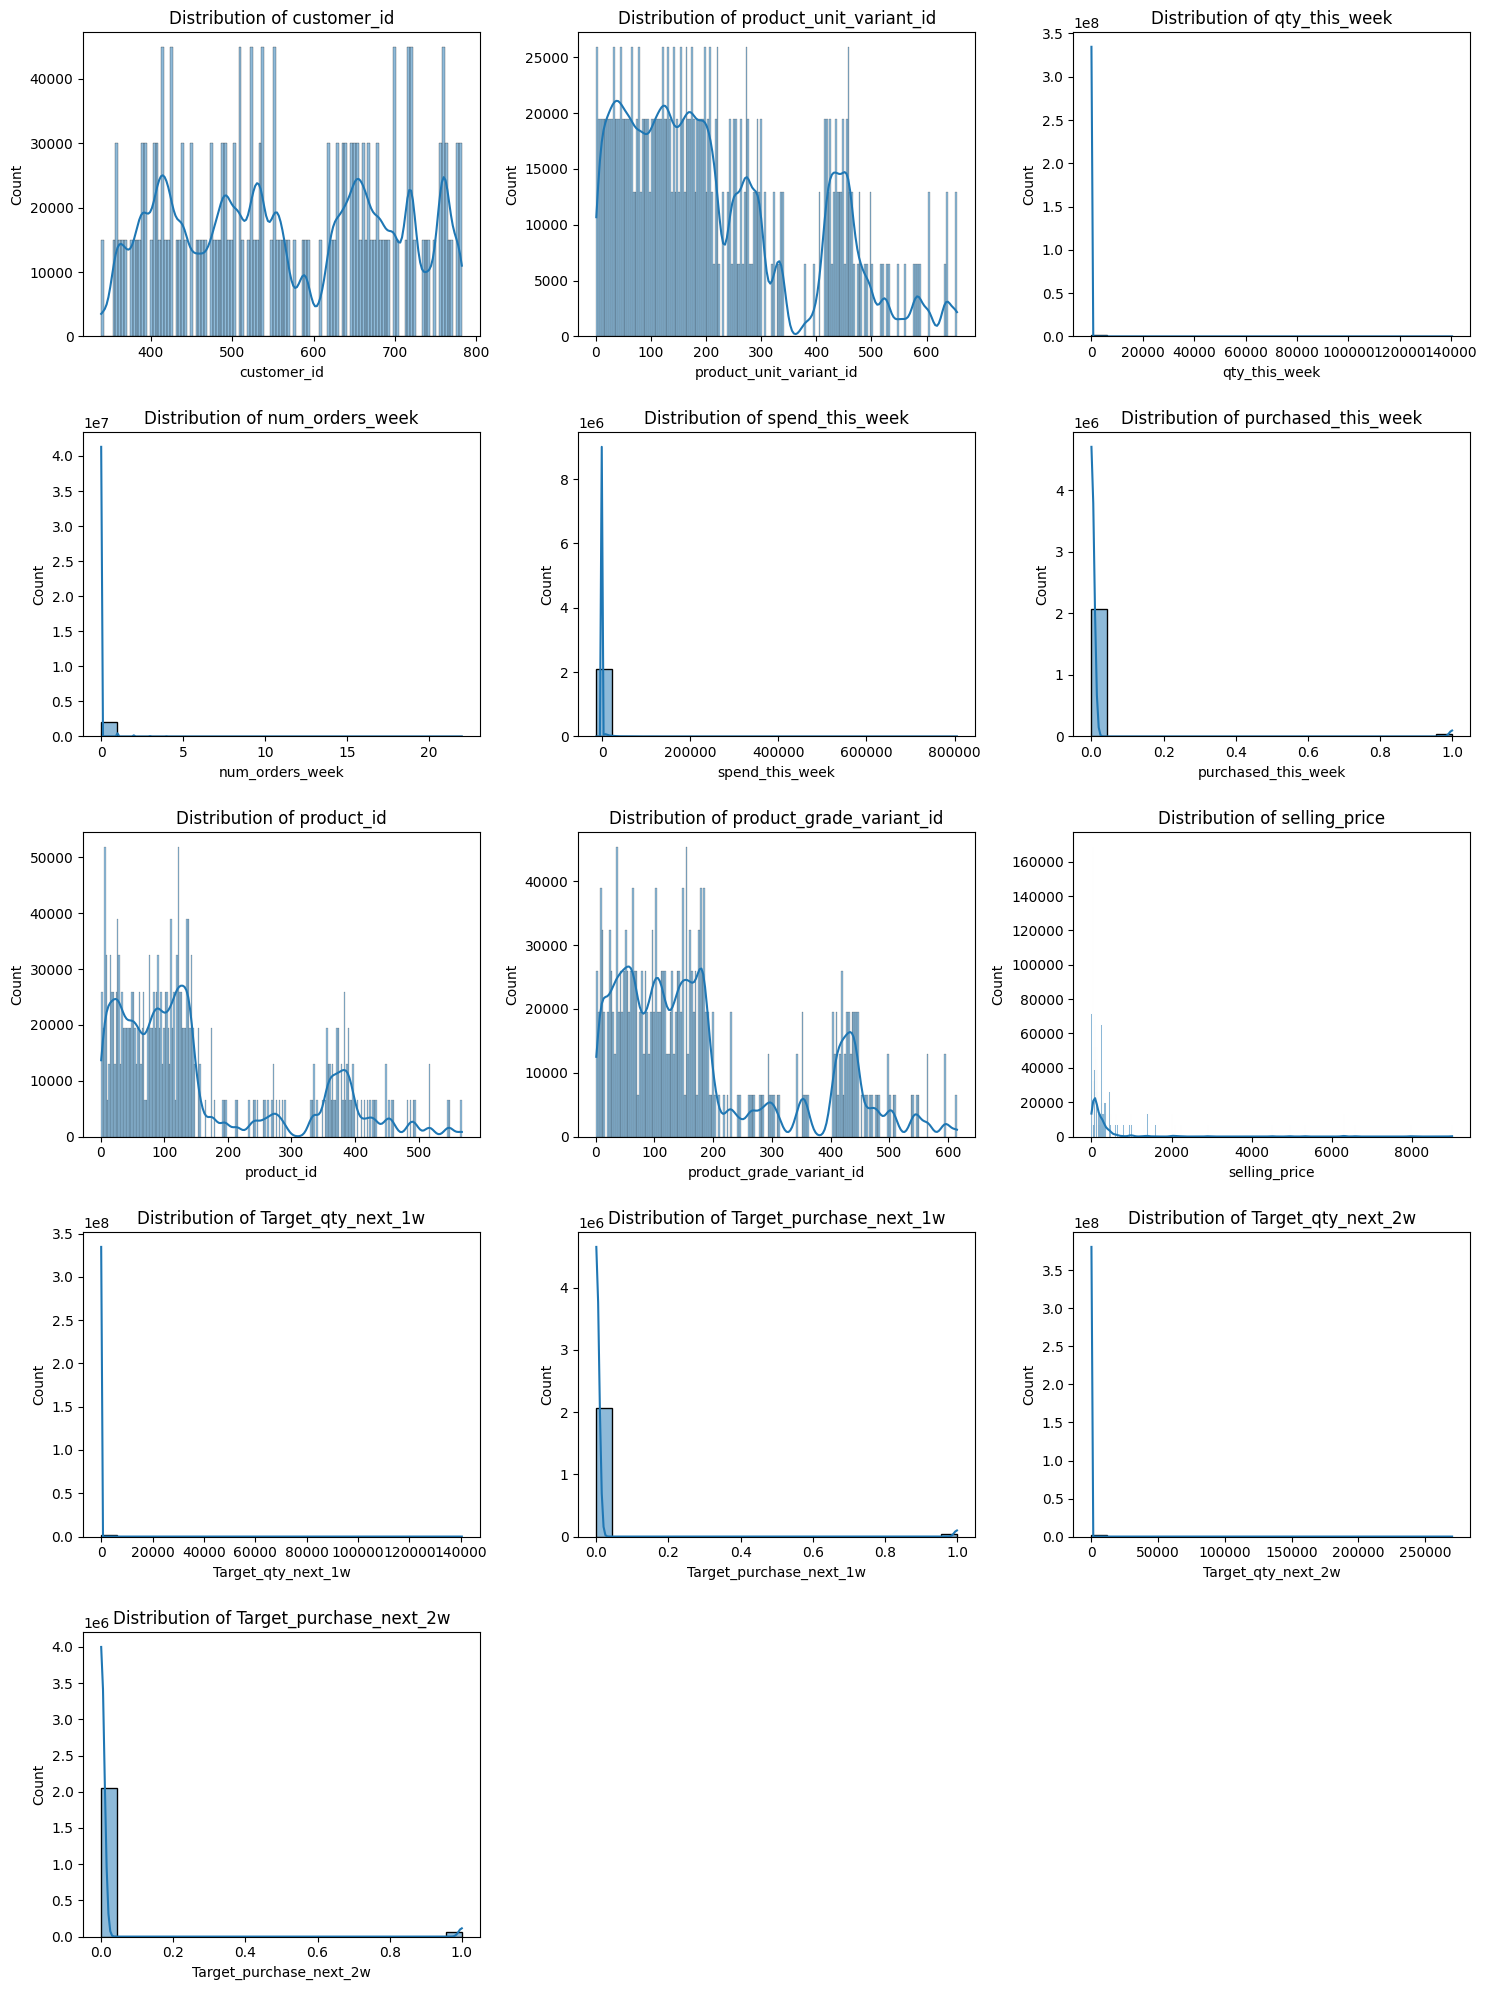

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

numeric_cols = [col for col in train.columns if train[col].dtype in ['int64', 'float64']]

# Calculate dynamic grid size to accommodate all numeric columns
num_plots = len(numeric_cols)
ncols = 3  # You can adjust the number of columns as desired
nrows = (num_plots + ncols - 1) // ncols # Ceiling division

plt.figure(figsize=(5 * ncols, 4 * nrows)) # Adjust figure size based on grid

for i, col in enumerate(numeric_cols):
    plt.subplot(nrows, ncols, i + 1)
    sns.histplot(train[col], kde=True)
    plt.title(f'Distribution of {col}') # Add title for clarity

plt.tight_layout()
plt.show()

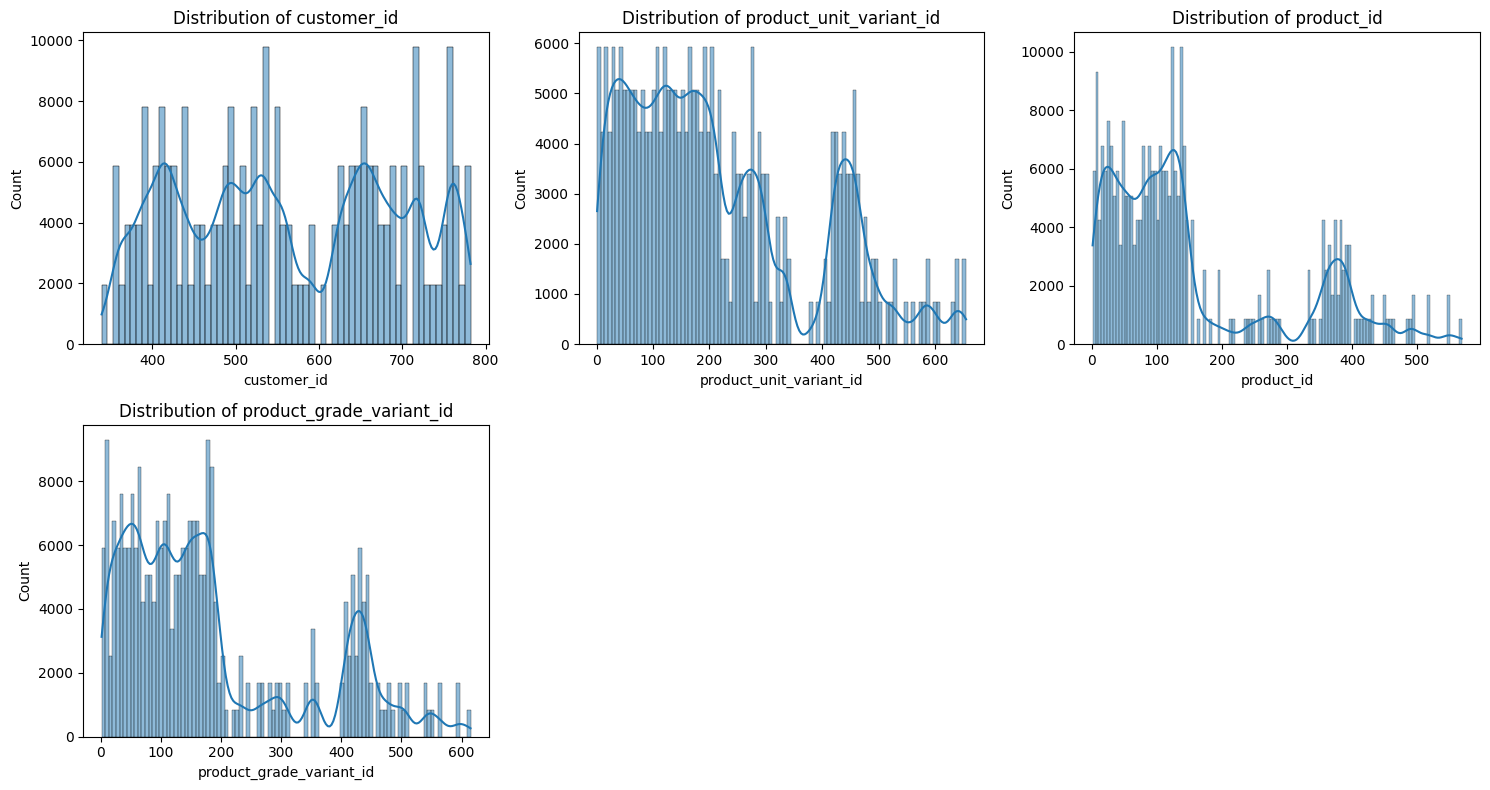

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

numeric_cols = [col for col in test.columns if test[col].dtype in ['int64', 'float64']]

# Calculate dynamic grid size to accommodate all numeric columns
num_plots = len(numeric_cols)
ncols = 3  # You can adjust the number of columns as desired
nrows = (num_plots + ncols - 1) // ncols # Ceiling division

plt.figure(figsize=(5 * ncols, 4 * nrows)) # Adjust figure size based on grid

for i, col in enumerate(numeric_cols):
    plt.subplot(nrows, ncols, i + 1)
    sns.histplot(test[col], kde=True)
    plt.title(f'Distribution of {col}') # Add title for clarity

plt.tight_layout()
plt.show()

# STAGE 5: Data preproccess and Feature Engineering

# Data preproccess

In [ ]:
train['week_start'] = pd.to_datetime(train['week_start'])
test['week_start'] = pd.to_datetime(test['week_start'])


train['month'] = train['week_start'].dt.month
train['week_number'] = train['week_start'].dt.isocalendar().week
train['year'] = train['week_start'].dt.year


test['month'] = test['week_start'].dt.month
test['week_number'] = test['week_start'].dt.isocalendar().week
test['year'] = test['week_start'].dt.year

In [ ]:
cols=['month','week_number','year']
for cols in train[cols]:
  print(train[cols].head())

0    10
1    10
2    10
3    10
4    10
Name: month, dtype: int32
0    44
1    44
2    44
3    44
4    44
Name: week_number, dtype: UInt32
0    2024
1    2024
2    2024
3    2024
4    2024
Name: year, dtype: int32


In [ ]:
print('create training features')
customer_features = pd.DataFrame()


customer_avg = train.groupby('customer_id')['spend_this_week'].mean().reset_index()
customer_avg.columns = ['customer_id', 'customer_avg_spend']



customer_total = train.groupby('customer_id')['purchased_this_week'].sum().reset_index()
customer_total.columns = ['customer_id', 'customer_total_purchases']


customer_features = customer_avg.merge(customer_total, on='customer_id')


# 3.2 Product features (from training data)
print("Creating product features...")
product_features = pd.DataFrame()


product_avg = train.groupby('product_unit_variant_id')['qty_this_week'].mean().reset_index()
product_avg.columns = ['product_unit_variant_id', 'product_avg_qty']

# How often product is purchased
product_freq = train.groupby('product_unit_variant_id')['purchased_this_week'].mean().reset_index()
product_freq.columns = ['product_unit_variant_id', 'product_purchase_freq']


product_features = product_avg.merge(product_freq, on='product_unit_variant_id')


print("Creating recent history features...")
train_sorted = train.sort_values(['customer_id', 'product_unit_variant_id', 'week_start'])


# Add recent purchase columns
train_sorted['last_week_qty'] = train_sorted.groupby(['customer_id', 'product_unit_variant_id'])['qty_this_week'].shift(1)
train_sorted['two_weeks_ago_qty'] = train_sorted.groupby(['customer_id', 'product_unit_variant_id'])['qty_this_week'].shift(2)


# Average of last 4 weeks
train_sorted['avg_last_10_weeks'] = train_sorted.groupby(['customer_id', 'product_unit_variant_id'])['qty_this_week'].transform(
    lambda x: x.rolling(10, min_periods=1).mean()
)

# Get the most recent values for each customer-product pair
recent_features = train_sorted.sort_values('week_start').groupby(['customer_id', 'product_unit_variant_id']).last().reset_index()
recent_features = recent_features[['customer_id', 'product_unit_variant_id', 'last_week_qty', 'two_weeks_ago_qty', 'avg_last_10_weeks']]

create training features
Creating product features...
Creating recent history features...


In [ ]:
recent_features.head()

,customer_id,product_unit_variant_id,last_week_qty,two_weeks_ago_qty,avg_last_10_weeks
0,339,1,0.0,0.0,0.0
1,339,2,0.0,0.0,0.0
2,339,3,2.0,0.0,1.2
3,339,4,0.0,0.0,0.0
4,339,5,0.0,0.0,0.8


In [ ]:
# Add features to training data
train_with_features = train.copy()
train_with_features = train_with_features.merge(customer_features, on='customer_id', how='left')
train_with_features = train_with_features.merge(product_features, on='product_unit_variant_id', how='left')
train_with_features = train_with_features.merge(recent_features, on=['customer_id', 'product_unit_variant_id'], how='left')


test_with_features = test.copy()
test_with_features = test_with_features.merge(customer_features, on='customer_id', how='left')
test_with_features = test_with_features.merge(product_features, on='product_unit_variant_id', how='left')
test_with_features = test_with_features.merge(recent_features, on=['customer_id', 'product_unit_variant_id'], how='left')





print(f"Training data now has {train_with_features.shape[1]} columns")
print(f"Test data now has {test_with_features.shape[1]} columns")

Training data now has 30 columns
Test data now has 21 columns


In [ ]:
train_with_features.head(2)

,ID,customer_id,product_unit_variant_id,week_start,qty_this_week,num_orders_week,spend_this_week,purchased_this_week,product_id,grade_name,...,month,week_number,year,customer_avg_spend,customer_total_purchases,product_avg_qty,product_purchase_freq,last_week_qty,two_weeks_ago_qty,avg_last_10_weeks
0,339_1_20241028,339,1,2024-10-28,0.0,0.0,0.0,0,65,GRADE_01,...,10,44,2024,667.843445,695,0.000039,0.000154,0.0,0.0,0.0
1,679_498_20241028,679,498,2024-10-28,0.0,0.0,0.0,0,430,GRADE_05,...,10,44,2024,0.980261,3,0.000000,0.000000,0.0,0.0,0.0


# Handle missing values by mode

In [ ]:
train_with_features = train_with_features.fillna(train_with_features.mode().iloc[0])
test_with_features = test_with_features.fillna(test_with_features.mode().iloc[0])

In [ ]:
target_features=['Target_qty_next_1w',
                 'Target_qty_next_2w',
                 'Target_purchase_next_1w',
                 'Target_purchase_next_2w'
                 ]

In [ ]:
do_not_use = ['ID',
              'customer_id',
              'product_unit_variant_id',
              'week_start'
              ]

In [ ]:
test_with_features.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 275796 entries, 0 to 275795
Data columns (total 21 columns):
 #   Column                    Non-Null Count   Dtype         
---  ------                    --------------   -----         
 0   ID                        275796 non-null  object        
 1   customer_id               275796 non-null  int64         
 2   product_unit_variant_id   275796 non-null  int64         
 3   week_start                275796 non-null  datetime64[ns]
 4   product_id                275796 non-null  int64         
 5   grade_name                275796 non-null  object        
 6   unit_name                 275796 non-null  object        
 7   product_grade_variant_id  275796 non-null  int64         
 8   customer_category         275796 non-null  object        
 9   customer_status           275796 non-null  object        
 10  customer_created_at       275796 non-null  object        
 11  month                     275796 non-null  int32         
 12  we

In [ ]:
train_with_features['week_number']=train_with_features['week_number'].astype('int64')
train_with_features['month']=train_with_features['month'].astype('int64')

test_with_features['week_number']=test_with_features['week_number'].astype('int64')
test_with_features['month']=test_with_features['month'].astype('int64')

In [ ]:
all_columns=list(test_with_features.columns)
test_features_columns=[]


for cols in all_columns:
  if cols not in do_not_use:
    if test_with_features[cols].dtype in ['int64','float64','float32','int32']:
      test_features_columns.append(cols)

In [ ]:
test_features_columns=test_features_columns
test_features_columns


['product_id',
 'product_grade_variant_id',
 'month',
 'week_number',
 'year',
 'customer_avg_spend',
 'customer_total_purchases',
 'product_avg_qty',
 'product_purchase_freq',
 'last_week_qty',
 'two_weeks_ago_qty',
 'avg_last_10_weeks']

In [ ]:
len(test_features_columns)

12

In [ ]:
test_features_columns

['product_id',
 'product_grade_variant_id',
 'month',
 'week_number',
 'year',
 'customer_avg_spend',
 'customer_total_purchases',
 'product_avg_qty',
 'product_purchase_freq',
 'last_week_qty',
 'two_weeks_ago_qty',
 'avg_last_10_weeks']

In [ ]:
all_columns=list(train_with_features.columns)
features_columns=[]


for cols in all_columns:
  if cols not in do_not_use and cols not in target_features:
    if train_with_features[cols].dtype in ['int64','float64','float32','int32']:
      # Changed to use test_features_columns for consistency
      if cols in test_features_columns:
        features_columns.append(cols)

# Data preparations for Training

In [ ]:
x_train=train_with_features[features_columns]
y_purchase_1w = train_with_features['Target_purchase_next_1w']
y_qty_1w = train_with_features['Target_qty_next_1w']
y_purchase_2w = train_with_features['Target_purchase_next_2w']
y_qty_2w = train_with_features['Target_qty_next_2w']

In [ ]:
train_list=x_train.columns.to_list()

In [ ]:
test_list=test_with_features.columns.to_list()

In [ ]:
drop_columns=[]
for cols in test_list:
  if cols not in train_list:
    drop_columns.append(cols)

In [ ]:
drop_columns

['ID',
 'customer_id',
 'product_unit_variant_id',
 'week_start',
 'grade_name',
 'unit_name',
 'customer_category',
 'customer_status',
 'customer_created_at']

In [ ]:
test_with_features=test_with_features.drop(drop_columns,axis=1)

In [ ]:
test_with_features.shape

(275796, 12)

In [ ]:
x_train_columns=x_train.columns.to_list()
x_train_columns

['qty_this_week',
 'num_orders_week',
 'spend_this_week',
 'purchased_this_week',
 'selling_price']

# TEST FEATURES DATASETS

In [ ]:
x_test=test_with_features

In [ ]:
x_test.shape,x_train.shape

((275796, 12), (2114436, 12))

#

In [ ]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(x_train)
x_test = test_with_features[test_features_columns]
X_test_scaled = scaler.transform(x_test) # Corrected to use transform only

In [ ]:
X_test_scaled

array([[ 0.02421882,  0.1215702 ,  0.80285446, ..., -0.00957707,
        -0.00549807, -0.00663407],
       [-0.13383155, -0.04230627,  0.80285446, ..., -0.00957707,
        -0.00549807, -0.00663407],
       [-0.50740513, -0.52082557,  0.80285446, ..., -0.00957707,
        -0.00549807, -0.00663407],
       ...,
       [-0.38527531, -0.36350415,  1.08914364, ..., -0.00957707,
        -0.00549807, -0.00663407],
       [ 2.4380789 ,  2.38306552,  1.08914364, ..., -0.00957707,
        -0.00549807, -0.00663407],
       [ 1.72685227,  1.69478433,  1.08914364, ..., -0.00957707,
        -0.00549807, -0.00663407]])

In [ ]:
X_train_scaled

array([[-0.63671906, -0.65192675,  1.08914364, ..., -0.00957707,
        -0.00549807, -0.00663407],
       [ 1.98548013,  1.93732151,  1.08914364, ..., -0.00957707,
        -0.00549807, -0.00663407],
       [ 2.01421656,  1.96354175,  1.08914364, ..., -0.00957707,
        -0.00549807, -0.00663407],
       ...,
       [-0.04043815,  0.06257467,  0.80285446, ..., -0.00957707,
        -0.00549807, -0.00663407],
       [ 1.7555887 ,  1.72755963,  0.80285446, ..., -0.00957707,
        -0.00549807, -0.00663407],
       [-0.34217066, -0.30450862,  0.80285446, ..., -0.00957707,
        -0.00549807, -0.00663407]])

In [ ]:
from lightgbm import LGBMClassifier, LGBMRegressor
from sklearn.preprocessing import StandardScaler

In [ ]:
# Model 1: Predict if customer will buy next week
print("Training Model 1: Will customer buy next week?")
model_buy_1w = LGBMClassifier(
    n_estimators=900,
    learning_rate=0.01,
    max_depth=20,
    random_state=42,
    verbose=-1
)
model_buy_1w.fit(X_train_scaled, y_purchase_1w)

# Model 2: Predict if customer will buy in 2 weeks
print("Training Model 2: Will customer buy in 2 weeks?")
model_buy_2w = LGBMClassifier(
    n_estimators=900,
    learning_rate=0.01,
    max_depth=20,
    random_state=42,
    verbose=-1
)
model_buy_2w.fit(X_train_scaled, y_purchase_2w)

# Model 3: Predict how much will be bought next week (only when purchase happens)
print("Training Model 3: How much will be bought next week?")
# Only use rows where purchase actually happened
buy_mask_1w = y_qty_1w > 0
if buy_mask_1w.sum() > 0:
    model_qty_1w = LGBMRegressor(
        n_estimators=900,
        learning_rate=0.01,
        max_depth=20,
        random_state=42,
        verbose=-1
    )
    model_qty_1w.fit(X_train_scaled[buy_mask_1w], y_qty_1w[buy_mask_1w])

# Model 4: Predict how much will be bought in 2 weeks (only when purchase happens)
print("Training Model 4: How much will be bought in 2 weeks?")
# Only use rows where purchase actually happened
buy_mask_2w = y_qty_2w > 0
if buy_mask_2w.sum() > 0:
    model_qty_2w = LGBMRegressor(
        n_estimators=900,
        learning_rate=0.01,
        max_depth=20,
        random_state=42,
        verbose=-1
    )
    model_qty_2w.fit(X_train_scaled[buy_mask_2w], y_qty_2w[buy_mask_2w])

Training Model 1: Will customer buy next week?
Training Model 2: Will customer buy in 2 weeks?
Training Model 3: How much will be bought next week?
Training Model 4: How much will be bought in 2 weeks?


In [82]:

# Predict purchase probabilities
prob_buy_1w = model_buy_1w.predict_proba(X_test_scaled)[:, 1]
prob_buy_2w = model_buy_2w.predict_proba(X_test_scaled)[:, 1]

# Predict quantities
if buy_mask_1w.sum() > 0:
    qty_1w = model_qty_1w.predict(X_test_scaled)
else:
    qty_1w = np.zeros(len(X_test_scaled))

if buy_mask_2w.sum() > 0:
    qty_2w = model_qty_2w.predict(X_test_scaled)
else:
    qty_2w = np.zeros(len(X_test_scaled))

# Adjust quantities: if purchase probability is low, quantity should be low
qty_final_1w = qty_1w * prob_buy_1w
qty_final_2w = qty_2w * prob_buy_2w

# Make sure no negative quantities
qty_final_1w = np.maximum(0, qty_final_1w)
qty_final_2w = np.maximum(0, qty_final_2w)

# Round to 2 decimal places
qty_final_1w = np.round(qty_final_1w, 2)
qty_final_2w = np.round(qty_final_2w, 2)

# Make sure probabilities are between 0.01 and 0.99
prob_buy_1w = np.clip(prob_buy_1w, 0.01, 0.99)
prob_buy_2w = np.clip(prob_buy_2w, 0.01, 0.99)




# Create the submission DataFrame
submission = pd.DataFrame({
    'ID': test['ID'],
    'Target_purchase_next_1w': prob_buy_1w,
    'Target_qty_next_1w': qty_final_1w,
    'Target_purchase_next_2w': prob_buy_2w,
    'Target_qty_next_2w': qty_final_2w
})


In [83]:
submission.to_csv(Output_Dir+'/aely_n_300_900_updated.csv',index=False)